# Peramalan Beban Listrik Per Jam Panama: Chronos-2, Chronos-Bolt, TimesFM 2.0, dan XGBoost

Penjelasan rinci setiap tahap ada di `LAPORAN_ANALISIS.md`.

## Tahap 0. Persiapan

Memuat pustaka dan menetapkan path, horizon, konteks, serta periode uji.

In [1]:
import warnings, json, time
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import xgboost as xgb
from scipy import stats
from statsmodels.tsa.seasonal import MSTL
from statsmodels.tsa.stattools import adfuller, kpss, acf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from huggingface_hub import snapshot_download
from chronos import BaseChronosPipeline
from transformers import TimesFmModelForPrediction

warnings.filterwarnings('ignore')
np.random.seed(42); torch.manual_seed(42)
DATA = Path('Panama_beban_listrik_per_jam_2015-2020_.xlsx')
MODEL_DIR, OUT, DASH = Path('models'), Path('outputs'), Path('dashboard')
for p in (MODEL_DIR, OUT, DASH):
    p.mkdir(exist_ok=True)
H, CTX = 24, 2048
QS = [i / 10 for i in range(1, 10)]
QCOLS = [f'q{q}' for q in QS]
TEST_START, COVID_START = pd.Timestamp('2020-01-01'), pd.Timestamp('2020-03-15')
VARIANTS = ['Chronos-2 + kovariat', 'Chronos-2 univariat', 'Chronos-Bolt', 'TimesFM-2.0', 'XGBoost']
COLORS = dict(zip(VARIANTS, ['#a3366f', '#d49ab8', '#a8690c', '#3d8a4a', '#3f5fc0']))
CITY_COLORS = {'Tocumen': '#1d5fa8', 'Santiago': '#c4701a', 'David': '#8c2d7a'}
CITY = {'toc': 'Tocumen', 'san': 'Santiago', 'dav': 'David'}
VAR = {'T2M': 'Suhu (°C)', 'QV2M': 'Kelembapan', 'TQL': 'Presipitasi cair', 'W2M': 'Angin (m/s)'}
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True,
                     'grid.color': '#e6e6e6', 'grid.linewidth': 0.6, 'axes.titleweight': 'bold', 'axes.titlesize': 11,
                     'axes.titlelocation': 'left', 'lines.linewidth': 1.4, 'font.size': 9.5, 'legend.frameon': False})
print('torch', torch.__version__, '| thread CPU:', torch.get_num_threads())

torch 2.8.0+cpu | thread CPU: 6


## Tahap 1. Memuat data

Data per jam dibaca dari Excel dan indeks waktunya ditetapkan berfrekuensi per jam.

In [2]:
df = pd.read_excel(DATA, sheet_name='data').set_index('datetime').asfreq('h')
y = df['nat_demand']
wcols = [c for c in df.columns if c.split('_')[0] in VAR]
print(f'Observasi: {len(df):,} | Rentang: {df.index.min()} s.d. {df.index.max()} | Kolom: {df.shape[1]}')
pd.read_excel(DATA, sheet_name='deskripsi')

Observasi: 48,048 | Rentang: 2015-01-03 01:00:00 s.d. 2020-06-27 00:00:00 | Kolom: 16


,kolom,deskripsi,satuan
0,datetime,"Tanggal-waktu, zona waktu Panama UTC−05:00",tanggal-waktu
1,nat_demand,Beban listrik nasional,MWh
2,T2M_toc,"Suhu pada ketinggian 2 meter di Tocumen, Kota ...",°C
3,QV2M_toc,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
4,TQL_toc,"Presipitasi cair (menurut README) di Tocumen, ...",l/m² (menurut README)
5,W2M_toc,Kecepatan angin pada ketinggian 2 meter di Toc...,m/s (menurut README)
6,T2M_san,Suhu pada ketinggian 2 meter di Kota Santiago,°C
7,QV2M_san,Kelembapan relatif pada ketinggian 2 meter (me...,% (menurut README)
8,TQL_san,Presipitasi cair (menurut README) di Kota Sant...,l/m² (menurut README)
9,W2M_san,Kecepatan angin pada ketinggian 2 meter di Kot...,m/s (menurut README)


Statistik deskriptif merangkum sebaran setiap variabel.

In [3]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
nat_demand,48048.0,1182.869,192.069,85.193,1020.057,1168.428,1327.564,1754.882
T2M_toc,48048.0,27.399,1.675,22.953,26.160,27.118,28.558,35.040
QV2M_toc,48048.0,0.018,0.002,0.012,0.017,0.019,0.020,0.023
TQL_toc,48048.0,0.080,0.066,0.000,0.026,0.065,0.117,0.521
W2M_toc,48048.0,13.391,7.296,0.009,7.545,12.182,18.661,39.230
T2M_san,48048.0,26.921,3.018,19.765,24.769,26.167,28.712,39.063
QV2M_san,48048.0,0.018,0.002,0.010,0.017,0.018,0.019,0.022
TQL_san,48048.0,0.106,0.086,0.000,0.037,0.086,0.157,0.485
W2M_san,48048.0,7.047,4.104,0.060,3.955,5.993,9.410,24.484
T2M_dav,48048.0,24.720,2.414,19.934,22.955,24.002,26.243,34.216


## Tahap 2. Prapemrosesan

Pemeriksaan kualitas memastikan deret per jam lengkap, tanpa nilai hilang maupun stempel waktu ganda.

In [4]:
cek = pd.Series({'Nilai hilang': int(df.isna().sum().sum()),
                 'Stempel waktu ganda': int(df.index.duplicated().sum()),
                 'Jam yang terlewat': int(len(pd.date_range(df.index.min(), df.index.max(), freq='h')) - len(df)),
                 'Beban <= 0': int((y <= 0).sum())})
cek.to_frame('jumlah')

,jumlah
Nilai hilang,0
Stempel waktu ganda,0
Jam yang terlewat,0
Beban <= 0,0


Anomali ditandai bila simpangan dari median bergulir mingguan melebihi 5 × MAD terskala.

In [5]:
dev = y - y.rolling(168, center=True, min_periods=24).median()
mad = 1.4826 * (dev - dev.median()).abs().median()
anom = y[dev.abs() > 5 * mad]
print(f'Titik anomali: {len(anom)} | ambang: {5 * mad:.1f} MWh')
y.nsmallest(5).round(1).to_frame('beban terendah (MWh)')

Titik anomali: 2 | ambang: 1079.4 MWh


,beban terendah (MWh)
datetime,
2019-01-20 12:00:00,85.2
2019-01-20 13:00:00,135.8
2019-01-20 14:00:00,263.6
2017-06-27 12:00:00,380.6
2019-01-20 15:00:00,417.4


Fitur kalender, lag beban ≥ 24 jam, dan cuaca disusun untuk XGBoost.

In [6]:
def make_features(s, ex):
    F = pd.DataFrame({'hour': s.index.hour, 'dow': s.index.dayofweek, 'month': s.index.month, 'doy': s.index.dayofyear}, index=s.index)
    for L in (24, 48, 72, 168, 336):
        F[f'lag{L}'] = s.shift(L)
    F['mean24_lag24'], F['mean168_lag24'] = s.shift(24).rolling(24).mean(), s.shift(24).rolling(168).mean()
    return F.join(ex[wcols + ['Holiday_ID', 'holiday', 'school']])

F = make_features(y, df)
ok = F.notna().all(axis=1)
print(f'Fitur: {F.shape[1]} | baris lengkap: {ok.sum():,}')
F.head(3).T.head(12)

Fitur: 26 | baris lengkap: 47,712


datetime,2015-01-03 01:00:00,2015-01-03 02:00:00,2015-01-03 03:00:00
hour,1.000000,2.000000,3.00000
dow,5.000000,5.000000,5.00000
month,1.000000,1.000000,1.00000
doy,3.000000,3.000000,3.00000
lag24,NaN,NaN,NaN
lag48,NaN,NaN,NaN
lag72,NaN,NaN,NaN
lag168,NaN,NaN,NaN
lag336,NaN,NaN,NaN
mean24_lag24,NaN,NaN,NaN


Backtest bergulir memakai origin setiap pukul 00.00 dari 1 Januari sampai 26 Juni 2020, dibagi menjadi regime Normal dan COVID-19.

In [7]:
origins = pd.date_range(TEST_START, y.index[-1] - pd.Timedelta(hours=H), freq='D')
pos = y.index.get_indexer(origins)
yv = y.to_numpy(dtype='float32')
Y_true = np.stack([yv[p + 1:p + 1 + H] for p in pos])
regime = np.where(origins < COVID_START, 'Normal', 'COVID-19')
tgt = np.concatenate([np.arange(p + 1, p + 1 + H) for p in pos])
ytr = y[y.index < TEST_START]
MASE_SCALE = (ytr - ytr.shift(168)).abs().mean()
FC, INFO = {}, {}
print(f'{len(origins)} origin | Normal: {(regime == "Normal").sum()} | COVID-19: {(regime == "COVID-19").sum()} | skala MASE: {MASE_SCALE:.2f} MWh')

178 origin | Normal: 74 | COVID-19: 104 | skala MASE: 58.37 MWh


Konteks 2.048 jam terakhir dan kovariat masa lalu serta masa depan disiapkan untuk *foundation model*.

In [8]:
def local_model(repo):
    path = MODEL_DIR / repo.split('/')[-1]
    if not (path / 'config.json').exists():
        snapshot_download(repo, local_dir=path, allow_patterns=['*.json', '*.safetensors'])
    return path

n_params = lambda m: sum(p.numel() for p in m.parameters()) / 1e6
KOV = ['T2M_toc', 'T2M_san', 'T2M_dav', 'QV2M_toc', 'holiday', 'school']
kv = df[KOV].to_numpy(dtype='float32')
c2_input = lambda p, fut: {'target': yv[p - CTX + 1:p + 1],
                           'past_covariates': {c: kv[p - CTX + 1:p + 1, i] for i, c in enumerate(KOV)},
                           'future_covariates': {c: fut[:, i] for i, c in enumerate(KOV)}}
ctx_list = [torch.tensor(yv[p - CTX + 1:p + 1]) for p in pos]
kov_inputs = [c2_input(p, kv[p + 1:p + 1 + H]) for p in pos]
print(f'{len(ctx_list)} konteks x {CTX} jam | kovariat: {KOV}')

178 konteks x 2048 jam | kovariat: ['T2M_toc', 'T2M_san', 'T2M_dav', 'QV2M_toc', 'holiday', 'school']


## Tahap 3. Analisis eksploratif beban

Ringkasan tahunan menunjukkan level dan pertumbuhan beban setiap tahun.

In [9]:
yr = y.groupby(y.index.year).agg(['mean', 'std', 'min', 'max', 'count'])
yr['tumbuh_%'] = yr['mean'].pct_change() * 100
yr.round(2)

,mean,std,min,max,count,tumbuh_%
datetime,,,,,,
2015,1131.53,194.15,509.84,1645.48,8711,NaN
2016,1157.19,190.29,744.43,1615.25,8784,2.27
2017,1182.32,188.96,380.59,1635.92,8760,2.17
2018,1205.68,185.45,826.78,1635.54,8760,1.98
2019,1243.58,189.14,85.19,1721.52,8760,3.14
2020,1170.23,176.12,821.85,1754.88,4273,-5.90


Deret per jam dan rata-rata mingguan memperlihatkan tren, musiman, dan penurunan saat COVID-19.

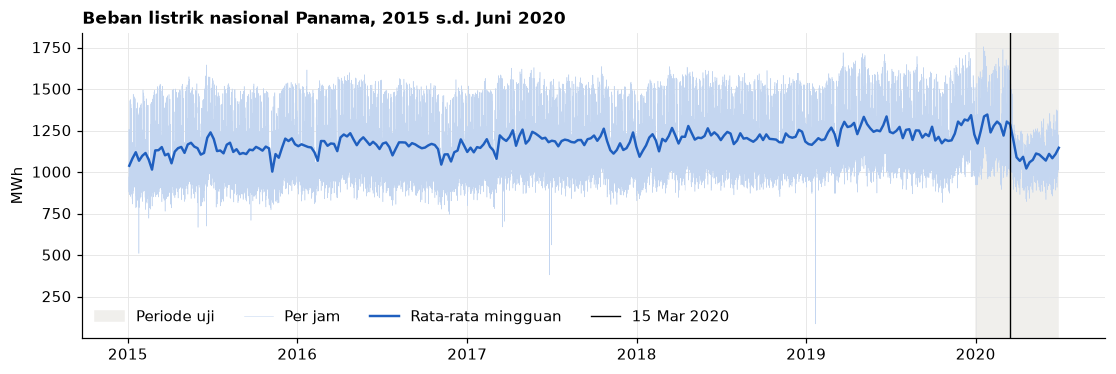

In [10]:
fig, ax = plt.subplots(figsize=(12, 3.6))
ax.axvspan(TEST_START, y.index[-1], color='#f0efec', zorder=0, label='Periode uji')
ax.plot(y.index, y, color='#c4d6f0', lw=0.35, label='Per jam')
ax.plot(y.resample('W').mean(), color='#1f5fbf', lw=1.6, label='Rata-rata mingguan')
ax.axvline(COVID_START, color='k', lw=0.9, label='15 Mar 2020')
ax.set(title='Beban listrik nasional Panama, 2015 s.d. Juni 2020', ylabel='MWh'); ax.legend(loc='lower left', ncol=4); plt.show()

Peta panas jam × hari dan profil hari libur memperlihatkan musiman harian, musiman mingguan, dan efek libur.

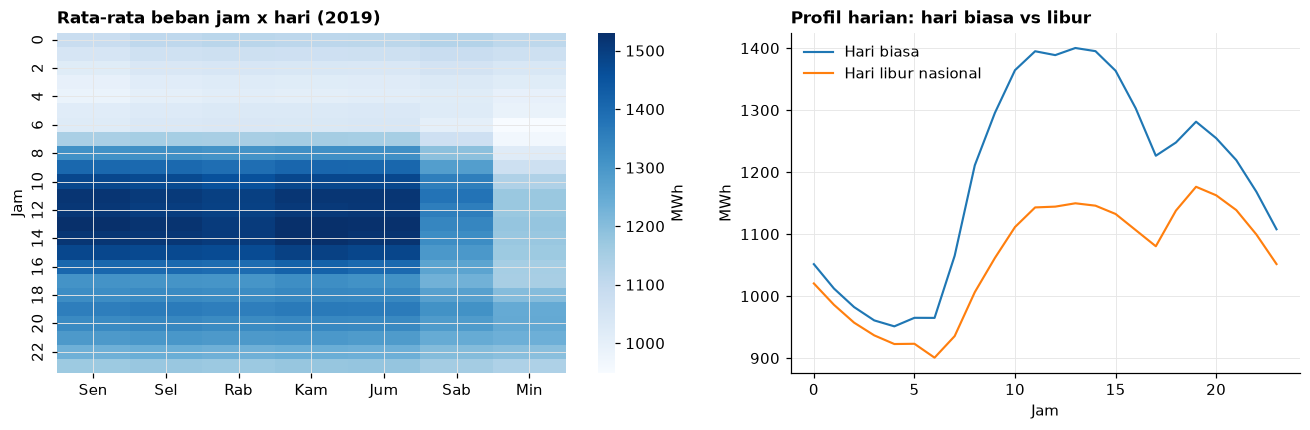

Rasio puncak/lembah profil 2019: 1.61


In [11]:
d19 = df.loc['2019']
prof = d19.pivot_table(index=d19.index.hour, columns=d19.index.dayofweek, values='nat_demand', aggfunc='mean')
prof.columns = ['Sen', 'Sel', 'Rab', 'Kam', 'Jum', 'Sab', 'Min']
hol = df.groupby([df.index.hour, 'holiday'])['nat_demand'].mean().unstack()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={'width_ratios': [1.25, 1]})
sns.heatmap(prof, cmap='Blues', ax=axes[0], cbar_kws={'label': 'MWh'}); axes[0].set(title='Rata-rata beban jam x hari (2019)', ylabel='Jam')
axes[1].plot(hol.index, hol[0], label='Hari biasa'); axes[1].plot(hol.index, hol[1], label='Hari libur nasional')
axes[1].set(title='Profil harian: hari biasa vs libur', xlabel='Jam', ylabel='MWh'); axes[1].legend()
plt.tight_layout(); plt.show()
print(f'Rasio puncak/lembah profil 2019: {prof.values.max() / prof.values.min():.2f}')

Uji t Welch menguji apakah rata-rata beban harian saat libur berbeda dari hari kerja biasa.

In [12]:
dd = df.resample('D').agg({'nat_demand': 'mean', 'holiday': 'max'})
dd = dd[dd.index.dayofweek < 5]
lib, bia = dd.loc[dd.holiday == 1, 'nat_demand'], dd.loc[dd.holiday == 0, 'nat_demand']
t_hol = stats.ttest_ind(lib, bia, equal_var=False)
print(f'Hari kerja: libur {lib.mean():.1f} vs biasa {bia.mean():.1f} MWh ({(lib.mean() / bia.mean() - 1) * 100:.1f}%) | t = {t_hol.statistic:.2f}, p = {t_hol.pvalue:.2e} | n libur = {len(lib)}')

Hari kerja: libur 1069.3 vs biasa 1226.0 MWh (-12.8%) | t = -16.11, p = 3.99e-28 | n libur = 84


Profil bulanan per tahun memperlihatkan pola musiman tahunan dan pertumbuhan beban.

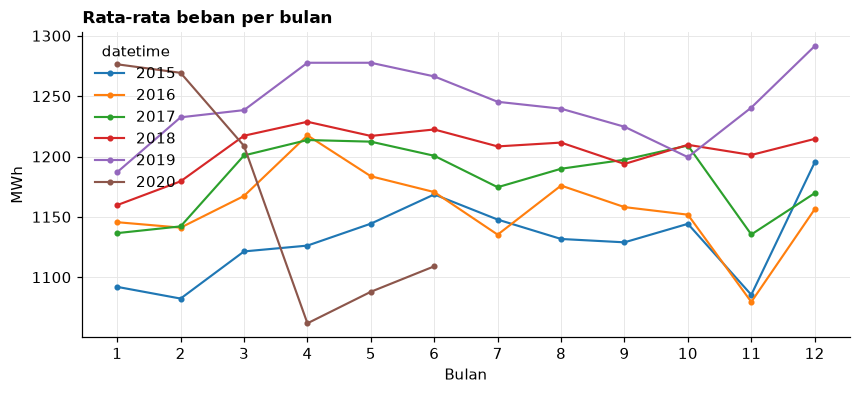

In [13]:
mon = y.groupby([y.index.year, y.index.month]).mean().unstack(0)
ax = mon.plot(figsize=(9, 3.6), marker='o', ms=3, title='Rata-rata beban per bulan')
ax.set(xlabel='Bulan', ylabel='MWh', xticks=range(1, 13)); plt.show()

Dekomposisi MSTL mengukur kekuatan tren serta musiman harian dan mingguan pada 2019.

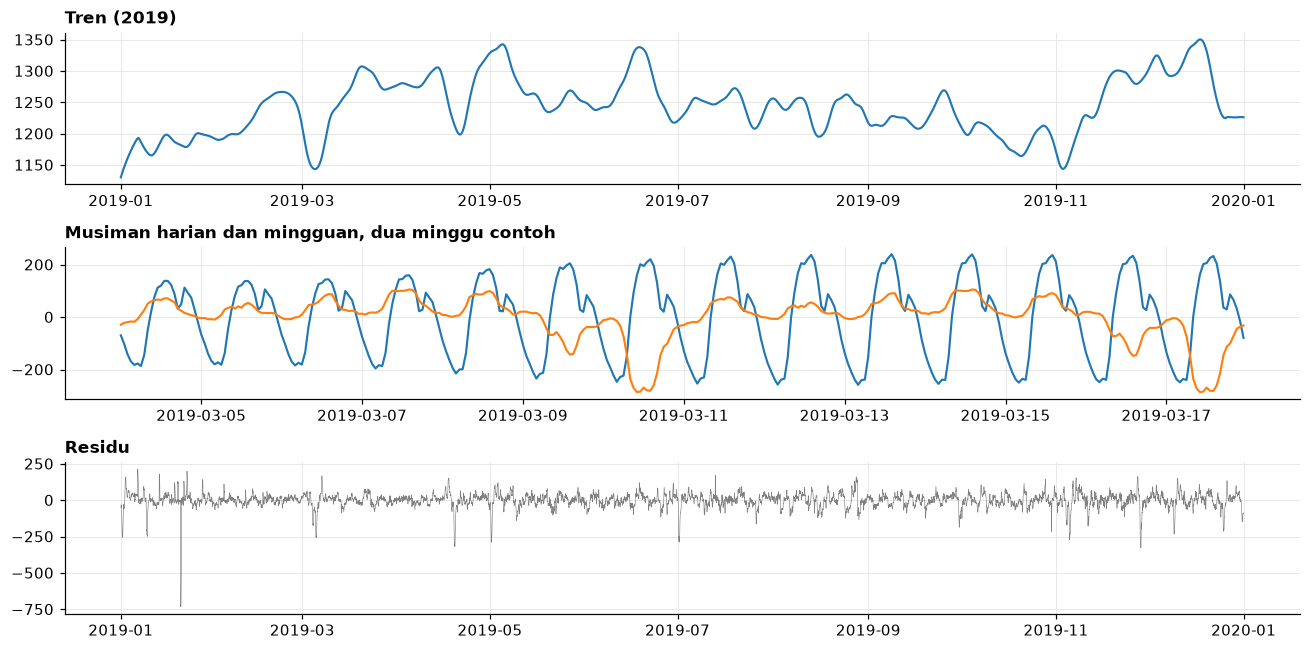

,kekuatan (0-1)
Tren,0.502
seasonal_24,0.906
seasonal_168,0.712


In [14]:
m = MSTL(y['2019'], periods=(24, 168)).fit()
R = m.resid
strength = {'Tren': 1 - R.var() / (m.trend + R).var()}
strength.update({c: 1 - R.var() / (m.seasonal[c] + R).var() for c in m.seasonal.columns})
fig, axes = plt.subplots(3, 1, figsize=(12, 6))
wk = slice('2019-03-04', '2019-03-17')
axes[0].plot(m.trend); axes[0].set_title('Tren (2019)')
axes[1].plot(m.seasonal['seasonal_24'][wk]); axes[1].plot(m.seasonal['seasonal_168'][wk]); axes[1].set_title('Musiman harian dan mingguan, dua minggu contoh')
axes[2].plot(R, color='grey', lw=0.4); axes[2].set_title('Residu')
plt.tight_layout(); plt.show()
pd.Series(strength).clip(lower=0).round(3).rename('kekuatan (0-1)').to_frame()

ACF dan PACF memperlihatkan ketergantungan beban pada lag 24 dan 168 jam.

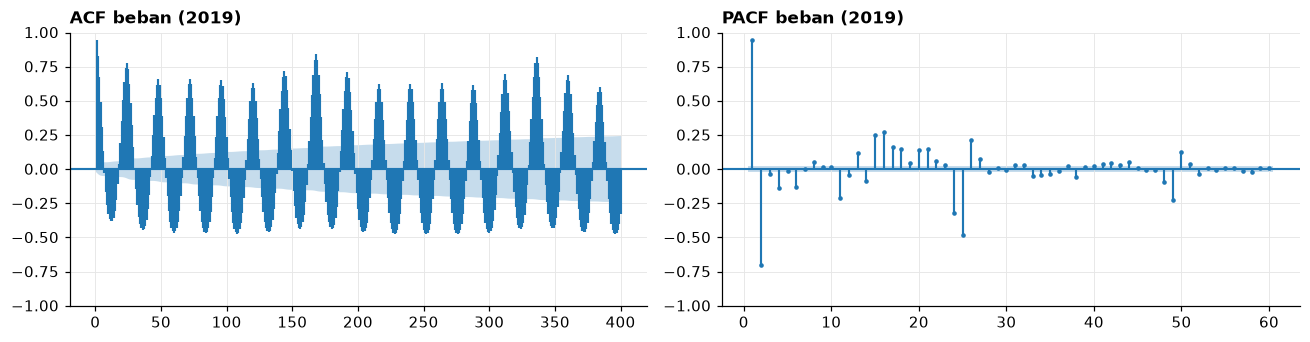

ACF lag 24 = 0.777 | lag 168 = 0.843


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.2))
plot_acf(y['2019'], lags=400, ax=axes[0], zero=False, markersize=0, title='ACF beban (2019)')
plot_pacf(y['2019'], lags=60, ax=axes[1], zero=False, markersize=2, method='ywm', title='PACF beban (2019)')
plt.tight_layout(); plt.show()
acf_v = acf(y['2019'], nlags=336)
print(f'ACF lag 24 = {acf_v[24]:.3f} | lag 168 = {acf_v[168]:.3f}')

Uji ADF dan KPSS memeriksa stasioneritas rata-rata beban harian.

In [16]:
yd = y.resample('D').mean()
rows = []
for nama, s in [('Level harian', yd), ('Beda pertama harian', yd.diff().dropna())]:
    a, k = adfuller(s, autolag='AIC'), kpss(s, regression='c', nlags='auto')
    rows.append([nama, a[0], a[1], k[0], k[1]])
stasioner = pd.DataFrame(rows, columns=['Deret', 'ADF stat', 'ADF p', 'KPSS stat', 'KPSS p'])
stasioner.round(4)

,Deret,ADF stat,ADF p,KPSS stat,KPSS p
0,Level harian,-3.5594,0.0066,3.0714,0.01
1,Beda pertama harian,-14.8039,0.0000,0.0542,0.10


## Tahap 4. Analisis cuaca tiga kota

Statistik per kota merangkum suhu, kelembapan, presipitasi, dan angin di Tocumen, Santiago, dan David.

In [17]:
w_stats = pd.DataFrame([{'Kota': CITY[c], 'Variabel': VAR[v], 'Rata-rata': df[f'{v}_{c}'].mean(), 'Simpangan baku': df[f'{v}_{c}'].std(),
                         'Min': df[f'{v}_{c}'].min(), 'Maks': df[f'{v}_{c}'].max()} for v in VAR for c in CITY])
w_stats.pivot(index='Variabel', columns='Kota', values='Rata-rata').round(4)

Kota,David,Santiago,Tocumen
Variabel,,,
Angin (m/s),3.5676,7.0467,13.3910
Kelembapan,0.0169,0.0178,0.0183
Presipitasi cair,0.1447,0.1063,0.0800
Suhu (°C),24.7195,26.9210,27.3991


Korelasi Pearson mengukur hubungan setiap variabel cuaca dengan beban pada skala per jam dan harian.

In [18]:
daily = df.resample('D').mean()
corr = pd.DataFrame({'r_per_jam': df[wcols].corrwith(y), 'r_harian': daily[wcols].corrwith(daily['nat_demand'])})
corr.sort_values('r_per_jam', ascending=False).round(3)

,r_per_jam,r_harian
T2M_toc,0.653,0.153
T2M_dav,0.648,0.140
T2M_san,0.627,0.112
W2M_san,0.192,-0.041
TQL_san,0.119,-0.125
W2M_toc,0.098,-0.007
TQL_toc,0.073,-0.165
TQL_dav,0.042,-0.096
QV2M_san,0.022,0.048
QV2M_dav,-0.002,0.066


Korelasi di dalam jam yang sama menghapus pola harian bersama, sehingga efek suhu yang tersisa terlihat lebih jujur.

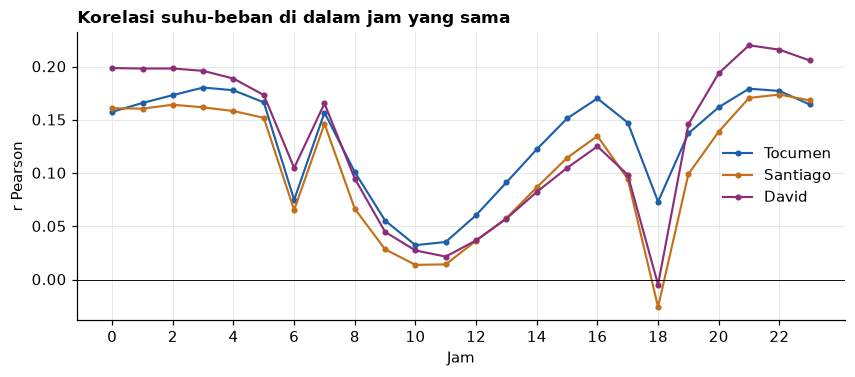

,Tocumen,Santiago,David
Suhu (°C),0.130,0.106,0.129
Kelembapan,0.080,0.063,0.075
Presipitasi cair,-0.131,-0.097,-0.073
Angin (m/s),0.016,-0.031,-0.055


In [19]:
r_jam = pd.DataFrame({CITY[c]: [df.loc[df.index.hour == h, f'T2M_{c}'].corr(y[y.index.hour == h]) for h in range(24)] for c in CITY})
fig, ax = plt.subplots(figsize=(9, 3.4))
r_jam.plot(ax=ax, marker='o', ms=3, color=[CITY_COLORS[c] for c in r_jam.columns]); ax.axhline(0, color='k', lw=0.6)
ax.set(title='Korelasi suhu-beban di dalam jam yang sama', xlabel='Jam', ylabel='r Pearson', xticks=range(0, 24, 2)); plt.show()
r_within = pd.DataFrame({CITY[c]: {VAR[v]: np.mean([df.loc[df.index.hour == h, f'{v}_{c}'].corr(y[y.index.hour == h]) for h in range(24)]) for v in VAR} for c in CITY})
r_within.round(3)

Plot sebar suhu harian terhadap beban harian pada hari kerja memperlihatkan bentuk hubungan di tiap kota.

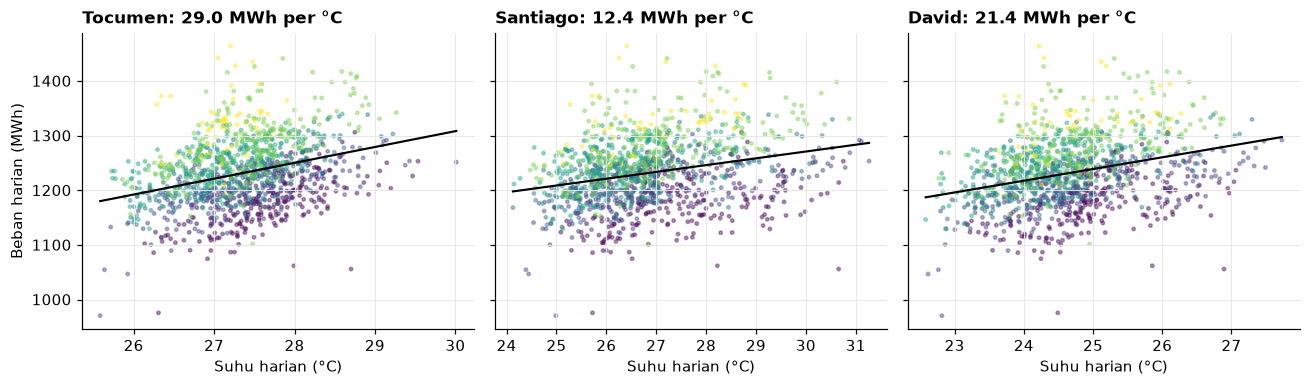

In [20]:
kerja = daily[(daily.index.dayofweek < 5) & (daily['holiday'] == 0) & (daily.index < COVID_START)]
fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
slope = {}
for ax, c in zip(axes, CITY):
    b = np.polyfit(kerja[f'T2M_{c}'], kerja['nat_demand'], 1); slope[CITY[c]] = b[0]
    ax.scatter(kerja[f'T2M_{c}'], kerja['nat_demand'], s=5, alpha=0.4, c=kerja.index.year, cmap='viridis')
    xs = np.linspace(kerja[f'T2M_{c}'].min(), kerja[f'T2M_{c}'].max(), 20); ax.plot(xs, np.polyval(b, xs), color='k')
    ax.set(title=f'{CITY[c]}: {b[0]:.1f} MWh per °C', xlabel='Suhu harian (°C)')
axes[0].set_ylabel('Beban harian (MWh)'); plt.tight_layout(); plt.show()

Profil harian beban dan suhu tiap kota diindeks terhadap rata-ratanya (100) agar bentuknya dapat dibandingkan pada satu sumbu.

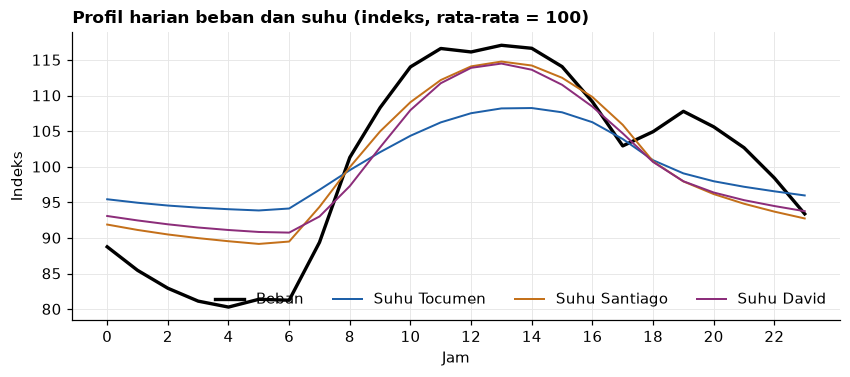

In [21]:
diurnal = df.groupby(df.index.hour)[['nat_demand'] + wcols].mean()
idx = diurnal / diurnal.mean() * 100
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.plot(idx.index, idx['nat_demand'], color='k', lw=2.2, label='Beban')
for c in CITY:
    ax.plot(idx.index, idx[f'T2M_{c}'], color=CITY_COLORS[CITY[c]], lw=1.3, label=f'Suhu {CITY[c]}')
ax.set(title='Profil harian beban dan suhu (indeks, rata-rata = 100)', xlabel='Jam', ylabel='Indeks', xticks=range(0, 24, 2)); ax.legend(ncol=4); plt.show()

## Tahap 5. Pemodelan

XGBoost dilatih pada data hingga Oktober 2019 dengan *early stopping* pada November sampai Desember 2019.

In [22]:
fit_i, val_i = ok & (F.index < '2019-11-01'), ok & (F.index >= '2019-11-01') & (F.index < TEST_START)
xgbm = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=7, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                        early_stopping_rounds=150, eval_metric='mae', n_jobs=-1, random_state=42)
t0 = time.time()
xgbm.fit(F[fit_i], y[fit_i], eval_set=[(F[val_i], y[val_i])], verbose=False)
FC['XGBoost'] = {'mean': xgbm.predict(F.iloc[tgt]).reshape(len(pos), H), 'q': None}
INFO['XGBoost'] = {'jenis': 'Machine learning (gradient boosting)', 'parameter_juta': np.nan, 'detik': time.time() - t0}
print(f'Latih: {fit_i.sum():,} jam | validasi: {val_i.sum():,} jam | iterasi terbaik: {xgbm.best_iteration} | MAE validasi: {xgbm.best_score:.2f} MWh')

Latih: 41,975 jam | validasi: 1,464 jam | iterasi terbaik: 151 | MAE validasi: 49.11 MWh


Kepentingan fitur XGBoost menunjukkan fitur yang paling banyak menurunkan galat.

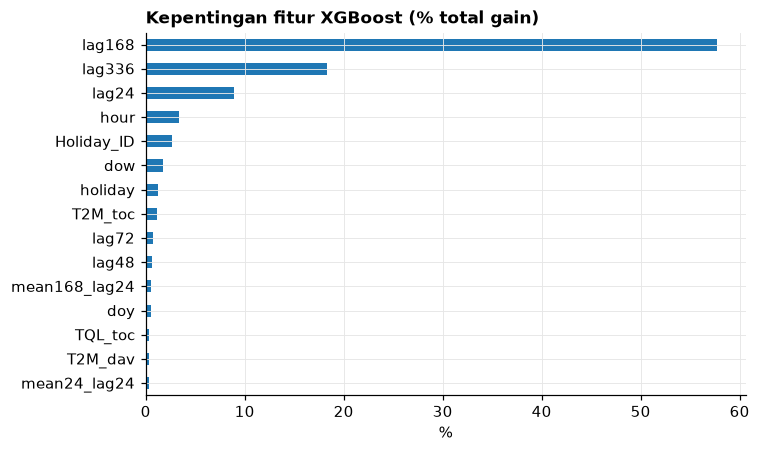

In [23]:
imp = pd.Series(xgbm.get_booster().get_score(importance_type='total_gain')).sort_values()
imp = (imp / imp.sum() * 100).tail(15)
ax = imp.plot.barh(figsize=(7, 4.2), title='Kepentingan fitur XGBoost (% total gain)'); ax.set_xlabel('%'); plt.tight_layout(); plt.show()

Chronos-Bolt meramal secara *zero-shot* hanya dari riwayat beban.

In [24]:
bolt = BaseChronosPipeline.from_pretrained(local_model('amazon/chronos-bolt-small'), device_map='cpu')
t0 = time.time()
q, mu = bolt.predict_quantiles(ctx_list, prediction_length=H, quantile_levels=QS)
FC['Chronos-Bolt'] = {'mean': mu.numpy(), 'q': np.sort(q.numpy(), axis=-1)}
INFO['Chronos-Bolt'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(bolt.model), 'detik': time.time() - t0}
del bolt
INFO['Chronos-Bolt']

{'jenis': 'Foundation model (zero-shot)',
 'parameter_juta': 47.718016,
 'detik': 11.464218378067017}

Chronos-2 meramal tanpa kovariat (univariat).

In [25]:
c2 = BaseChronosPipeline.from_pretrained(local_model('amazon/chronos-2'), device_map='cpu')
c2_out = lambda q, mu: {'mean': torch.stack(mu).squeeze(1).numpy(), 'q': np.sort(torch.stack(q).squeeze(1).numpy(), axis=-1)}
t0 = time.time()
FC['Chronos-2 univariat'] = c2_out(*c2.predict_quantiles(ctx_list, prediction_length=H, quantile_levels=QS))
INFO['Chronos-2 univariat'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(c2.model), 'detik': time.time() - t0}
INFO['Chronos-2 univariat']

{'jenis': 'Foundation model (zero-shot)',
 'parameter_juta': 119.477664,
 'detik': 47.96524167060852}

Chronos-2 meramal dengan kovariat suhu tiga kota, kelembapan Tocumen, hari libur, dan masa sekolah.

In [26]:
t0 = time.time()
FC['Chronos-2 + kovariat'] = c2_out(*c2.predict_quantiles(kov_inputs, prediction_length=H, quantile_levels=QS))
INFO['Chronos-2 + kovariat'] = {'jenis': 'Foundation model (zero-shot + kovariat)', 'parameter_juta': n_params(c2.model), 'detik': time.time() - t0}
INFO['Chronos-2 + kovariat']

{'jenis': 'Foundation model (zero-shot + kovariat)',
 'parameter_juta': 119.477664,
 'detik': 388.611145734787}

TimesFM 2.0 meramal secara *zero-shot* hanya dari riwayat beban.

In [27]:
tfm = TimesFmModelForPrediction.from_pretrained(local_model('google/timesfm-2.0-500m-pytorch')).eval()
def tfm_predict(ctxs):
    mus, qs = [], []
    with torch.no_grad():
        for i in range(0, len(ctxs), 16):
            o = tfm(past_values=ctxs[i:i + 16], freq=[0] * len(ctxs[i:i + 16]), return_dict=True)
            mus.append(o.mean_predictions[:, :H]); qs.append(o.full_predictions[:, :H, 1:])
    return {'mean': torch.cat(mus).numpy(), 'q': np.sort(torch.cat(qs).numpy(), axis=-1)}
t0 = time.time()
FC['TimesFM-2.0'] = tfm_predict(ctx_list)
INFO['TimesFM-2.0'] = {'jenis': 'Foundation model (zero-shot)', 'parameter_juta': n_params(tfm), 'detik': time.time() - t0}
del tfm
INFO['TimesFM-2.0']

{'jenis': 'Foundation model (zero-shot)',
 'parameter_juta': 498.82896,
 'detik': 131.3372781276703}

## Tahap 6. Evaluasi

Seluruh ramalan disatukan dalam satu tabel panjang dan disimpan ke `outputs/`.

In [28]:
ts = np.stack([y.index[p + 1:p + 1 + H] for p in pos])
base = pd.DataFrame({'origin': np.repeat(origins, H), 'ts': ts.ravel(), 'h': np.tile(np.arange(1, H + 1), len(pos)),
                     'regime': np.repeat(regime, H), 'actual': Y_true.ravel()})
parts = []
for name in VARIANTS:
    d = base.assign(model=name, mean=FC[name]['mean'].ravel())
    if FC[name]['q'] is not None:
        d = d.assign(**{c: FC[name]['q'][..., j].ravel() for j, c in enumerate(QCOLS)})
    parts.append(d)
fc_long = pd.concat(parts, ignore_index=True)
fc_long.to_csv(OUT / 'forecast_backtest.csv', index=False)
print(fc_long.shape)

(21360, 16)


MAE, RMSE, MAPE, MASE, *weighted quantile loss*, dan cakupan interval 80% dihitung untuk setiap model.

In [29]:
def metrik(g):
    e = g['actual'] - g['mean']
    out = {'MAE': e.abs().mean(), 'RMSE': np.sqrt((e ** 2).mean()), 'MAPE (%)': (e.abs() / g['actual']).mean() * 100,
           'MASE': e.abs().mean() / MASE_SCALE, 'WQL': np.nan, 'Cakupan 80% (%)': np.nan}
    if g[QCOLS[0]].notna().all():
        yq, Q, tau = g['actual'].to_numpy()[:, None], g[QCOLS].to_numpy(), np.array(QS)
        out['WQL'] = (2 * np.maximum(tau * (yq - Q), (tau - 1) * (yq - Q)).sum(axis=0) / np.abs(yq).sum()).mean()
        out['Cakupan 80% (%)'] = ((yq[:, 0] >= Q[:, 0]) & (yq[:, 0] <= Q[:, -1])).mean() * 100
    return pd.Series(out)

overall = fc_long.groupby('model')[['actual', 'mean'] + QCOLS].apply(metrik).sort_values('MAE')
overall.to_csv(OUT / 'metrik_keseluruhan.csv')
best = overall.index[0]
overall.round(3)

,MAE,RMSE,MAPE (%),MASE,WQL,Cakupan 80% (%)
model,,,,,,
Chronos-2 + kovariat,32.891,48.005,2.793,0.564,0.022,74.485
Chronos-2 univariat,33.495,50.939,2.854,0.574,0.023,74.930
Chronos-Bolt,37.253,56.259,3.182,0.638,0.025,80.009
TimesFM-2.0,37.976,56.580,3.221,0.651,0.026,74.953
XGBoost,48.605,69.858,4.186,0.833,NaN,NaN


Metrik yang sama dihitung terpisah untuk regime Normal dan COVID-19.

In [30]:
by_reg = fc_long.groupby(['regime', 'model'])[['actual', 'mean'] + QCOLS].apply(metrik)
by_reg.to_csv(OUT / 'metrik_per_regime.csv')
by_reg[['MAE', 'MAPE (%)', 'Cakupan 80% (%)']].unstack(0).swaplevel(axis=1).sort_index(axis=1).loc[overall.index].round(3)

regime                      COVID-19                           Normal          \
                     Cakupan 80% (%)     MAE MAPE (%) Cakupan 80% (%)     MAE   
model                                                                           
Chronos-2 + kovariat          72.396  30.724    2.772          77.421  35.937   
Chronos-2 univariat           72.436  32.758    2.939          78.435  34.529   
Chronos-Bolt                  76.643  35.684    3.217          84.741  39.457   
TimesFM-2.0                   69.792  36.606    3.274          82.207  39.901   
XGBoost                          NaN  49.572    4.533             NaN  47.247   

regime                         
                     MAPE (%)  
model                          
Chronos-2 + kovariat    2.822  
Chronos-2 univariat     2.735  
Chronos-Bolt            3.134  
TimesFM-2.0             3.146  
XGBoost                 3.699

Grafik MAPE per regime membandingkan akurasi model secara visual.

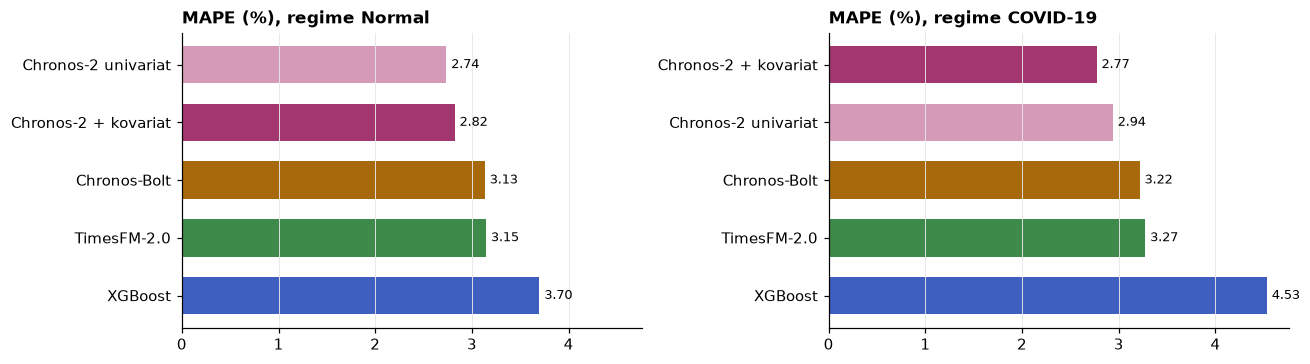

In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.4), sharex=True)
for ax, reg in zip(axes, ['Normal', 'COVID-19']):
    s = by_reg.loc[reg, 'MAPE (%)'].sort_values(ascending=False)
    ax.barh(s.index, s.values, color=[COLORS[m] for m in s.index], height=0.65)
    for i, v in enumerate(s.values):
        ax.text(v + 0.05, i, f'{v:.2f}', va='center', fontsize=8.5)
    ax.set(title=f'MAPE (%), regime {reg}'); ax.grid(axis='y', visible=False)
plt.tight_layout(); plt.show()

Galat menurut horizon memperlihatkan perubahan akurasi dari jam ke-1 sampai jam ke-24.

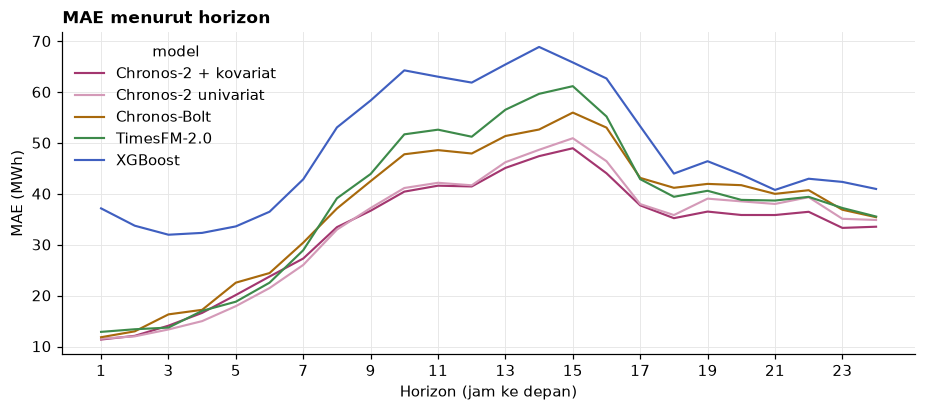

In [32]:
hz = fc_long.assign(ae=(fc_long['actual'] - fc_long['mean']).abs()).pivot_table(index='h', columns='model', values='ae', aggfunc='mean')[VARIANTS]
ax = hz.plot(figsize=(10, 3.8), color=[COLORS[m] for m in VARIANTS], title='MAE menurut horizon')
ax.set(xlabel='Horizon (jam ke depan)', ylabel='MAE (MWh)', xticks=range(1, 25, 2)); plt.show()

Contoh satu minggu di tiap regime membandingkan ramalan model terbaik dan XGBoost dengan nilai aktual.

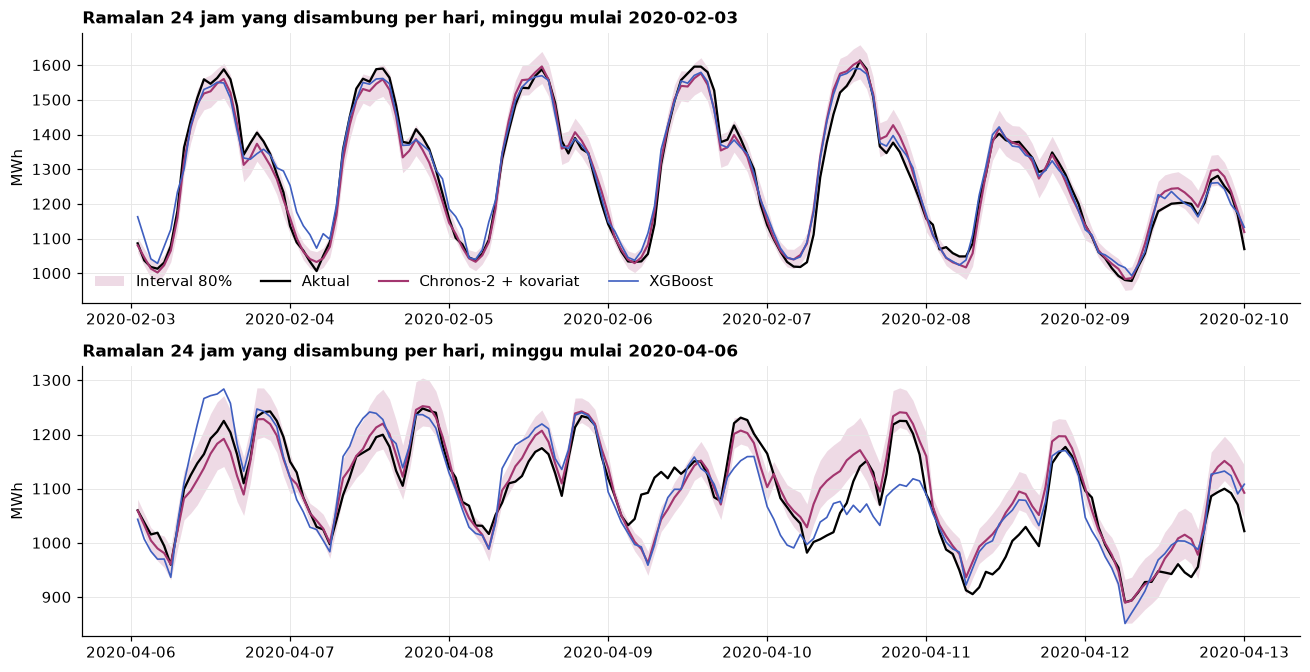

In [33]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.2))
for ax, start in zip(axes, ['2020-02-03', '2020-04-06']):
    w = fc_long[(fc_long.origin >= start) & (fc_long.origin < pd.Timestamp(start) + pd.Timedelta(days=7))]
    b, x = w[w.model == best], w[w.model == 'XGBoost']
    ax.fill_between(b.ts, b['q0.1'], b['q0.9'], color=COLORS[best], alpha=0.18, lw=0, label='Interval 80%')
    ax.plot(b.ts, b.actual, color='k', lw=1.5, label='Aktual')
    ax.plot(b.ts, b['q0.5'], color=COLORS[best], label=best)
    ax.plot(x.ts, x['mean'], color=COLORS['XGBoost'], lw=1.1, label='XGBoost')
    ax.set(title=f'Ramalan 24 jam yang disambung per hari, minggu mulai {start}', ylabel='MWh')
axes[0].legend(ncol=4, loc='lower left'); plt.tight_layout(); plt.show()

Uji Diebold-Mariano dengan varians HAC menguji apakah selisih akurasi harian antarmodel signifikan.

In [34]:
def dm_test(l1, l2, lag=5):
    d = l1 - l2; n = len(d); db = d.mean()
    g = [np.mean((d[k:] - db) * (d[:n - k] - db)) for k in range(lag + 1)]
    v = g[0] + 2 * sum((1 - k / (lag + 1)) * g[k] for k in range(1, lag + 1))
    s = db / np.sqrt(v / n)
    return s, 2 * stats.t.sf(abs(s), n - 1)

dae = fc_long.assign(ae=(fc_long['actual'] - fc_long['mean']).abs()).pivot_table(index=['origin', 'regime'], columns='model', values='ae', aggfunc='mean')
pairs = [(best, m) for m in VARIANTS if m != best]
if ('Chronos-2 + kovariat', 'Chronos-2 univariat') not in pairs:
    pairs.append(('Chronos-2 + kovariat', 'Chronos-2 univariat'))
rows = []
for a, b_ in pairs:
    for reg, sub in [('Semua', dae), ('Normal', dae.xs('Normal', level='regime')), ('COVID-19', dae.xs('COVID-19', level='regime'))]:
        s, p = dm_test(sub[a].to_numpy(), sub[b_].to_numpy())
        rows.append({'Model A': a, 'Model B': b_, 'Regime': reg, 'Selisih MAE (A-B)': (sub[a] - sub[b_]).mean(), 'DM': s, 'p-value': p})
dm = pd.DataFrame(rows)
dm['Kesimpulan (alpha 5%)'] = np.where(dm['p-value'] < 0.05, np.where(dm['DM'] < 0, 'A lebih akurat', 'B lebih akurat'), 'Tidak berbeda signifikan')
dm.to_csv(OUT / 'uji_diebold_mariano.csv', index=False)
dm.round(4)

,Model A,Model B,Regime,Selisih MAE (A-B),DM,p-value,Kesimpulan (alpha 5%)
0,Chronos-2 + kovariat,Chronos-2 univariat,Semua,-0.6035,-0.6276,0.5311,Tidak berbeda signifikan
1,Chronos-2 + kovariat,Chronos-2 univariat,Normal,1.4071,0.7821,0.4367,Tidak berbeda signifikan
2,Chronos-2 + kovariat,Chronos-2 univariat,COVID-19,-2.0342,-2.1648,0.0327,A lebih akurat
3,Chronos-2 + kovariat,Chronos-Bolt,Semua,-4.3616,-2.9550,0.0036,A lebih akurat
4,Chronos-2 + kovariat,Chronos-Bolt,Normal,-3.5201,-1.2335,0.2214,Tidak berbeda signifikan
5,Chronos-2 + kovariat,Chronos-Bolt,COVID-19,-4.9603,-3.3567,0.0011,A lebih akurat
6,Chronos-2 + kovariat,TimesFM-2.0,Semua,-5.0847,-3.2191,0.0015,A lebih akurat
7,Chronos-2 + kovariat,TimesFM-2.0,Normal,-3.9649,-1.6308,0.1072,Tidak berbeda signifikan
8,Chronos-2 + kovariat,TimesFM-2.0,COVID-19,-5.8814,-2.8270,0.0056,A lebih akurat
9,Chronos-2 + kovariat,XGBoost,Semua,-15.7142,-3.5120,0.0006,A lebih akurat


Ringkasan jenis, ukuran, dan waktu komputasi tiap model.

In [35]:
pd.DataFrame(INFO).T.loc[VARIANTS].round(2)

,jenis,parameter_juta,detik
Chronos-2 + kovariat,Foundation model (zero-shot + kovariat),119.477664,388.611146
Chronos-2 univariat,Foundation model (zero-shot),119.477664,47.965242
Chronos-Bolt,Foundation model (zero-shot),47.718016,11.464218
TimesFM-2.0,Foundation model (zero-shot),498.82896,131.337278
XGBoost,Machine learning (gradient boosting),NaN,4.417735


## Tahap 7. Simulasi skenario suhu

XGBoost dihitung ulang untuk geseran suhu −3 sampai +3 °C pada tiap kota dan pada ketiga kota sekaligus.

In [36]:
OFFSETS = [-3, -2, -1, 0, 1, 2, 3]
TEMP = {'Tocumen': ['T2M_toc'], 'Santiago': ['T2M_san'], 'David': ['T2M_dav'], 'Semua kota': ['T2M_toc', 'T2M_san', 'T2M_dav']}
def xgb_scen(X, cols, d):
    X = X.copy(); X[cols] += d
    return xgbm.predict(X)
Xbt = F.iloc[tgt]
xgb_sc = {k: {d: xgb_scen(Xbt, cols, d).reshape(len(pos), H) for d in OFFSETS} for k, cols in TEMP.items()}
sens_xgb = {k: (v[1] - v[0]).mean() for k, v in xgb_sc.items()}
print('XGBoost, perubahan rata-rata ramalan per +1 °C (MWh):', {k: round(float(v), 2) for k, v in sens_xgb.items()})

XGBoost, perubahan rata-rata ramalan per +1 °C (MWh): {'Tocumen': 4.5, 'Santiago': 0.92, 'David': 1.25, 'Semua kota': 6.85}


Chronos-2 dengan kovariat dihitung ulang untuk skenario yang sama pada 12 hari contoh.

In [37]:
SC_DAYS = pd.to_datetime(['2020-01-09', '2020-01-22', '2020-02-05', '2020-02-25', '2020-03-04', '2020-03-11',
                          '2020-03-25', '2020-04-10', '2020-04-22', '2020-05-06', '2020-05-20', '2020-06-10'])
sc_pos = y.index.get_indexer(SC_DAYS)
ki = {c: KOV.index(c) for c in ['T2M_toc', 'T2M_san', 'T2M_dav']}
def c2_scenarios(p, fut):
    jobs, keys = [c2_input(p, fut)], [('base', 0)]
    for k, cols in TEMP.items():
        for d in OFFSETS:
            if d:
                f = fut.copy(); f[:, [ki[c] for c in cols]] += d
                jobs.append(c2_input(p, f)); keys.append((k, d))
    return jobs, keys
jobs, keys = [], []
for p in sc_pos:
    j, k = c2_scenarios(p, kv[p + 1:p + 1 + H]); jobs += j; keys += [(p,) + kk for kk in k]
t0 = time.time()
q, mu = c2.predict_quantiles(jobs, prediction_length=H, quantile_levels=QS)
mu = torch.stack(mu).squeeze(1).numpy()
c2_sc = {}
for (p, k, d), m_ in zip(keys, mu):
    c2_sc.setdefault(p, {})[(k, d)] = m_
for p in sc_pos:
    for k in TEMP:
        c2_sc[p][(k, 0)] = c2_sc[p][('base', 0)]
print(f'{len(jobs)} ramalan skenario dalam {time.time() - t0:.0f} detik')

300 ramalan skenario dalam 722 detik


Sensitivitas rata-rata ramalan terhadap kenaikan suhu 1 °C dirangkum per model dan kota.

In [38]:
idx_sc = [list(pos).index(p) for p in sc_pos]
sens = pd.DataFrame({
    'XGBoost (178 hari)': {k: (xgb_sc[k][1] - xgb_sc[k][0]).mean() for k in TEMP},
    'XGBoost (12 hari contoh)': {k: (xgb_sc[k][1][idx_sc] - xgb_sc[k][0][idx_sc]).mean() for k in TEMP},
    'Chronos-2 + kovariat (12 hari contoh)': {k: np.mean([c2_sc[p][(k, 1)] - c2_sc[p][(k, 0)] for p in sc_pos]) for k in TEMP},
    'Chronos-2 + kovariat, +3 °C (12 hari)': {k: np.mean([c2_sc[p][(k, 3)] - c2_sc[p][(k, 0)] for p in sc_pos]) for k in TEMP}})
sens.to_csv(OUT / 'sensitivitas_suhu.csv')
sens.round(2)

,XGBoost (178 hari),XGBoost (12 hari contoh),Chronos-2 + kovariat (12 hari contoh),"Chronos-2 + kovariat, +3 °C (12 hari)"
Tocumen,4.50,4.78,12.03,27.43
Santiago,0.92,0.77,3.91,7.39
David,1.25,1.14,6.16,12.40
Semua kota,6.85,6.80,19.51,46.59


## Tahap 8. Ramalan 24 jam ke depan

Keempat model meramal 24 jam setelah akhir data, dengan cuaca masa depan diasumsikan sama dengan 24 jam terakhir dan tanpa hari libur.

In [39]:
fut_idx = pd.date_range(y.index[-1] + pd.Timedelta(hours=1), periods=H, freq='h')
ex_fut = df[wcols + ['Holiday_ID', 'holiday', 'school']].iloc[-H:].copy()
ex_fut.index = fut_idx
ex_fut[['Holiday_ID', 'holiday']] = 0
F_fut = make_features(pd.concat([y, pd.Series(np.nan, index=fut_idx)]), pd.concat([df, ex_fut]))[F.columns].loc[fut_idx]
kv_fut = ex_fut[KOV].to_numpy(dtype='float32')
p_end = len(y) - 1
ctx_end = [torch.tensor(yv[-CTX:])]
FUT = {'XGBoost': {'mean': xgbm.predict(F_fut), 'q': None},
       'Chronos-2 univariat': {k: v[0] for k, v in c2_out(*c2.predict_quantiles(ctx_end, prediction_length=H, quantile_levels=QS)).items()},
       }
tfm = TimesFmModelForPrediction.from_pretrained(MODEL_DIR / 'timesfm-2.0-500m-pytorch').eval()
FUT['TimesFM-2.0'] = {k: v[0] for k, v in tfm_predict(ctx_end).items()}
del tfm
bolt = BaseChronosPipeline.from_pretrained(MODEL_DIR / 'chronos-bolt-small', device_map='cpu')
q, mu = bolt.predict_quantiles(ctx_end, prediction_length=H, quantile_levels=QS)
FUT['Chronos-Bolt'] = {'mean': mu.numpy()[0], 'q': np.sort(q.numpy(), axis=-1)[0]}
del bolt
jobs, keys = c2_scenarios(p_end, kv_fut)
q, mu = c2.predict_quantiles(jobs, prediction_length=H, quantile_levels=QS)
c2_sc['future'] = dict(zip(keys, torch.stack(mu).squeeze(1).numpy()))
for k in TEMP:
    c2_sc['future'][(k, 0)] = c2_sc['future'][('base', 0)]
FUT['Chronos-2 + kovariat'] = {'mean': c2_sc['future'][('base', 0)], 'q': np.sort(torch.stack(q).squeeze(1).numpy(), axis=-1)[0]}
xgb_fut_sc = {k: {d: xgb_scen(F_fut, cols, d) for d in OFFSETS} for k, cols in TEMP.items()}
future = pd.DataFrame({m: FUT[m]['mean'] for m in VARIANTS}, index=fut_idx)
future.to_csv(OUT / 'forecast_masa_depan_24jam.csv')
future.round(1).head()

,Chronos-2 + kovariat,Chronos-2 univariat,Chronos-Bolt,TimesFM-2.0,XGBoost
2020-06-27 01:00:00,986.099976,991.099976,987.200012,990.400024,1045.400024
2020-06-27 02:00:00,965.400024,965.900024,963.099976,962.400024,1023.700012
2020-06-27 03:00:00,950.400024,944.299988,945.200012,945.500000,1002.700012
2020-06-27 04:00:00,940.099976,924.700012,931.700012,929.599976,979.400024
2020-06-27 05:00:00,936.599976,912.700012,912.599976,914.500000,974.900024


Grafik menampilkan tujuh hari terakhir dan ramalan 24 jam dari keempat model.

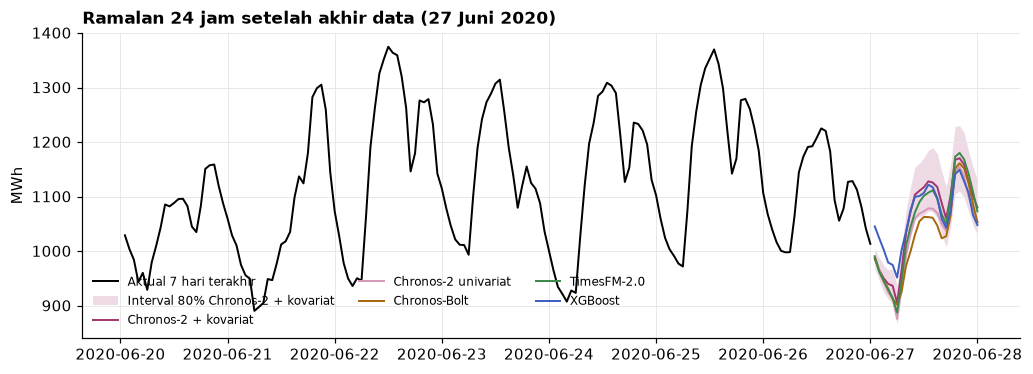

In [40]:
hist = y.iloc[-24 * 7:]
fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(hist.index, hist, color='k', lw=1.3, label='Aktual 7 hari terakhir')
b = FUT['Chronos-2 + kovariat']['q']
ax.fill_between(fut_idx, b[:, 0], b[:, -1], color=COLORS['Chronos-2 + kovariat'], alpha=0.18, lw=0, label='Interval 80% Chronos-2 + kovariat')
for m in VARIANTS:
    ax.plot(fut_idx, FUT[m]['mean'], color=COLORS[m], lw=1.3, label=m)
ax.set(title='Ramalan 24 jam setelah akhir data (27 Juni 2020)', ylabel='MWh'); ax.legend(ncol=3, loc='lower left', fontsize=8); plt.show()

## Tahap 9. Penyimpanan model

XGBoost disimpan ke `models/` lalu dimuat ulang untuk memastikan prediksinya identik dengan hasil backtest.

In [41]:
xgbm.save_model(MODEL_DIR / 'xgb_beban.json')
xgb_load = xgb.XGBRegressor(); xgb_load.load_model(MODEL_DIR / 'xgb_beban.json')
assert np.allclose(xgb_load.predict(F.iloc[tgt]).reshape(len(pos), H), FC['XGBoost']['mean'], atol=1e-3)
for f in sorted(MODEL_DIR.iterdir()):
    size = sum(x.stat().st_size for x in f.rglob('*') if x.is_file()) if f.is_dir() else f.stat().st_size
    print(f'{f.name:<28} {size / 1e6:8.1f} MB')

chronos-2                       477.9 MB
chronos-bolt-small              190.9 MB
sarimax_dhr.pkl                  27.6 MB
sarimax_w.pkl                     1.0 MB
timesfm-2.0-500m-pytorch       1995.4 MB
xgb_beban.json                    3.6 MB


## Tahap 10. Ekspor ke dashboard

Ringkasan hasil diekspor ke `dashboard/data.js` untuk dashboard GitHub Pages dan Streamlit.

In [42]:
r1 = lambda a: np.round(np.asarray(a, dtype=float), 1).tolist()
r3 = lambda a: np.round(np.asarray(a, dtype=float), 3).tolist()
tbl = lambda d: json.loads(pd.DataFrame(d).to_json(orient='split', double_precision=4))
fmt = lambda idx, f='%Y-%m-%d %H:%M': [t.strftime(f) for t in idx]
day_hol = df['holiday'].resample('D').max()
SC_LIST = [(p, d.strftime('%Y-%m-%d')) for p, d in zip(sc_pos, SC_DAYS)] + [('future', fut_idx[0].strftime('%Y-%m-%d'))]
DATA_OUT = {
    'meta': {'n_obs': len(y), 'start': str(y.index[0]), 'end': str(y.index[-1]), 'n_origin': len(pos), 'H': H, 'CTX': CTX,
             'test_start': str(TEST_START.date()), 'covid_start': str(COVID_START.date()), 'mase_scale': round(float(MASE_SCALE), 2),
             'best': best, 'variants': VARIANTS, 'kov': KOV, 'offsets': OFFSETS, 'cities': list(TEMP)},
    'hourly': {'start': str(y.index[0]), 'values': np.round(yv).astype(int).tolist()},
    'yearly': tbl(yr.round(2)), 'heat': {'z': r1(prof)}, 'holiday_profile': {'biasa': r1(hol[0]), 'libur': r1(hol[1])},
    'holiday_test': {'libur': round(float(lib.mean()), 1), 'biasa': round(float(bia.mean()), 1), 't': round(float(t_hol.statistic), 2),
                     'p': float(t_hol.pvalue), 'n_libur': int(len(lib))},
    'monthly': {str(k): r1(v.dropna()) for k, v in mon.items()}, 'strength': {k: round(max(0, float(v)), 3) for k, v in strength.items()},
    'acf': r3(acf_v), 'stationarity': tbl(stasioner.round(4)), 'anomaly': {'n': int(len(anom)), 'ts': fmt(anom.index), 'v': r1(anom)},
    'weather': {
        'daily': {'dates': fmt(daily.index, '%Y-%m-%d'), 'load': r1(daily['nat_demand']), 'holiday': daily['holiday'].round().astype(int).tolist(),
                  **{c: r3(daily[c]) for c in wcols}},
        'diurnal': {c: r3(diurnal[c]) for c in ['nat_demand'] + wcols},
        'monthly': {c: r3(df[c].groupby(df.index.month).mean()) for c in wcols},
        'corr': tbl(corr.round(3)), 'r_hour': {k: r3(v) for k, v in r_jam.items()}, 'r_within': tbl(r_within.round(3)),
        'stats': tbl(w_stats.round(4)), 'slope': {k: round(float(v), 2) for k, v in slope.items()}},
    'overall': tbl(overall), 'by_regime': tbl(by_reg.reset_index()), 'horizon': {m: r1(hz[m]) for m in VARIANTS},
    'dm': tbl(dm), 'info': tbl(pd.DataFrame(INFO).T.loc[VARIANTS]), 'importance': {'f': imp.index.tolist(), 'v': r1(imp)},
    'backtest': {'origins': fmt(origins, '%Y-%m-%d'), 'regime': regime.tolist(), 'holiday': [int(day_hol[o]) for o in origins], 'actual': r1(Y_true),
                 'mean': {m: r1(FC[m]['mean']) for m in VARIANTS},
                 'band': {m: {'lo': r1(FC[m]['q'][..., 0]), 'hi': r1(FC[m]['q'][..., -1])} for m in VARIANTS if FC[m]['q'] is not None}},
    'scenario': {'days': [d for _, d in SC_LIST],
                 'actual': [r1(Y_true[list(pos).index(p)]) if p != 'future' else None for p, _ in SC_LIST],
                 'xgb': {k: {str(d): [r1(xgb_sc[k][d][list(pos).index(p)]) if p != 'future' else r1(xgb_fut_sc[k][d]) for p, _ in SC_LIST] for d in OFFSETS} for k in TEMP},
                 'c2': {k: {str(d): [r1(c2_sc[p][(k, d)]) for p, _ in SC_LIST] for d in OFFSETS} for k in TEMP},
                 'sens': tbl(sens.round(2))},
    'future': {'ts': fmt(fut_idx), 'hist_ts': fmt(hist.index), 'hist': r1(hist),
               'mean': {m: r1(FUT[m]['mean']) for m in VARIANTS},
               'band': {m: {'lo': r1(FUT[m]['q'][:, 0]), 'hi': r1(FUT[m]['q'][:, -1])} for m in VARIANTS if FUT[m]['q'] is not None}}}
(DASH / 'data.js').write_text('window.DATA = ' + json.dumps(DATA_OUT, separators=(',', ':'), allow_nan=False) + ';', encoding='utf-8')
print(f"dashboard/data.js: {(DASH / 'data.js').stat().st_size / 1e6:.2f} MB")

dashboard/data.js: 0.99 MB
